In [226]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

In [227]:
df=pd.read_csv('../data/startup_funding.csv')

<div style="
background-color: #2a0101; 
text-align: center;
color: #f3f4f5;
font-size: 30px;
font-weight: bold;
">
BASIC UNDERSTANDING OF DATA
</div>

In [228]:
df.head(2)

,Sr No,Date dd/mm/yyyy,Startup Name,Industry Vertical,SubVertical,City Location,Investors Name,InvestmentnType,Amount in USD,Remarks
0,1,09/01/2020,BYJU’S,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,"20,00,00,000",NaN
1,2,13/01/2020,Shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,"80,48,394",NaN


In [229]:
df.shape

(3044, 10)

In [230]:
df.columns

Index(['Sr No', 'Date dd/mm/yyyy', 'Startup Name', 'Industry Vertical',
       'SubVertical', 'City  Location', 'Investors Name', 'InvestmentnType',
       'Amount in USD', 'Remarks'],
      dtype='str')

<div style="
background-color: #2a0101; 
text-align: center;
color: #f3f4f5;
font-size: 15px;
font-weight: bold;
padding: 10px;
">
FIX COLUMN NAMES 
</div>

In [231]:
df=df.rename(columns={"Date dd/mm/yyyy":"date","Sr No":"SN","City  Location":"City Location"})

In [232]:
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

In [233]:
df.columns

Index(['sn', 'date', 'startup_name', 'industry_vertical', 'subvertical',
       'city_location', 'investors_name', 'investmentntype', 'amount_in_usd',
       'remarks'],
      dtype='str')

In [234]:
df.duplicated().sum()

np.int64(0)

<div style="
background-color: #2a0101; 
text-align: center;
color: #f3f4f5;
font-size: 15px;
font-weight: bold;
padding: 10px;
">
HANDLING MISSING VALUES 
</div>

In [235]:
df.isnull().sum()

sn                      0
date                    0
startup_name            0
industry_vertical     171
subvertical           936
city_location         180
investors_name         24
investmentntype         4
amount_in_usd         960
remarks              2625
dtype: int64

In [236]:
#check missing percentage
df.isnull().mean()*100


sn                    0.000000
date                  0.000000
startup_name          0.000000
industry_vertical     5.617608
subvertical          30.749014
city_location         5.913272
investors_name        0.788436
investmentntype       0.131406
amount_in_usd        31.537451
remarks              86.235217
dtype: float64

In [239]:
# Remove rows with missing values only in columns where less than 2% of the values are missing
cols = [col for col in df.columns
        if (df[col].isnull().mean() < 0.02) & (df[col].isnull().mean() > 0)]
cols

['investors_name', 'investmentntype']

In [277]:
df[df[cols].isnull().any(axis=1)].head(2)

,sn,date,startup_name,industry_vertical,subvertical,city_location,investors_name,investmentntype,amount_in_usd,remarks
13,14,16/12/2019,InCred,Finance,Non-Banking Financial Company,Mumbai,NaN,Debt Funding,"59,00,000",NaN
30,31,19/11/2019,Furtados School of Music,Education,Music Education,Tulangan,IAN Fund and DSG Consumer Partners,NaN,"20,00,00,000",NaN


In [269]:
len(df[cols].dropna())/len(df)

0.9908015768725361

In [271]:
new_df=df[cols].dropna()
df.shape ,  new_df.shape

((3044, 10), (3016, 2))

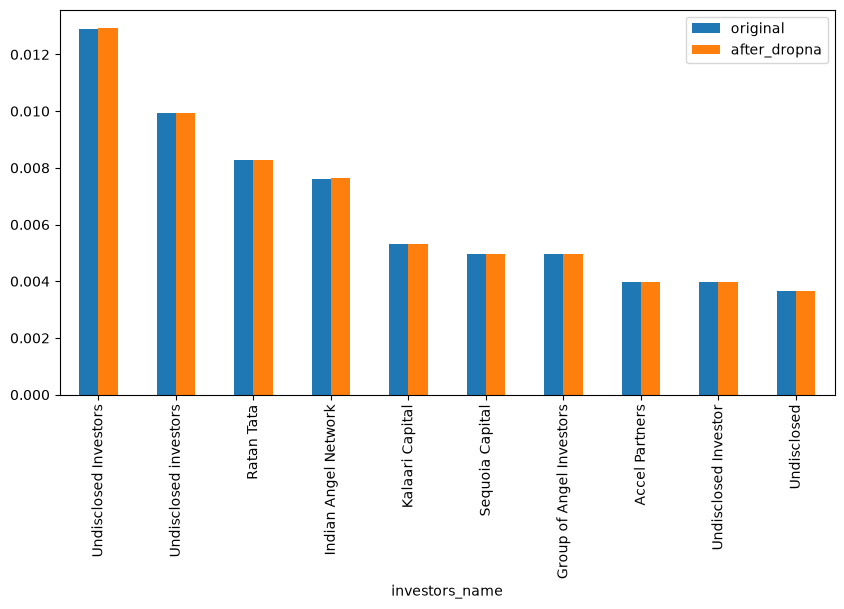

In [279]:
orig = df['investors_name'].value_counts(normalize=True).head(10)
new = new_df['investors_name'].value_counts(normalize=True).head(10)

pd.DataFrame({'original': orig, 'after_dropna': new}).plot(kind='bar', figsize=(10,5))
plt.show()

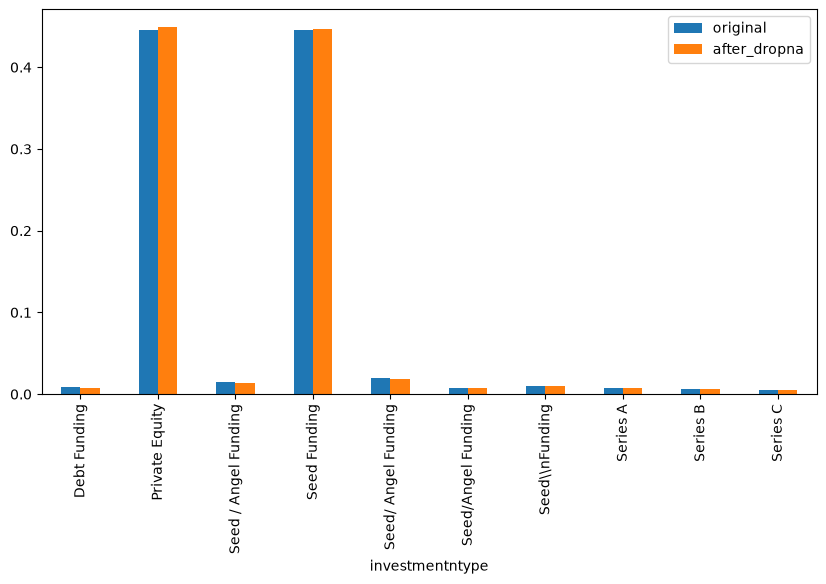

In [280]:
orig = df['investmentntype'].value_counts(normalize=True).head(10)
new = new_df['investmentntype'].value_counts(normalize=True).head(10)

pd.DataFrame({'original': orig, 'after_dropna': new}).plot(kind='bar', figsize=(10,5))
plt.show()